In [2]:
# 02 SENSITIVITY ANALYSIS: ANALYSIS OF FACTORIAL RESULTS
#Experiments are run by run_factorial.py.
# This notebook summarises the results, 
# tests the factors statistically and records the chosen baseline settings.

In [3]:
%pip install statsmodels
import pandas as pd                                                    #LIBRARY FOR DATA TABLES
import numpy as np                                                     #LIBRARY FOR BASIC CALCULATIONS
import matplotlib.pyplot as plt                                        #LIBRARY FOR PLOTTING
from scipy import stats                                                #PAIRED T-TESTS
import statsmodels.formula.api as smf                                  #REGRESSION MODELS FOR ANOVA
from statsmodels.stats.anova import anova_lm                           #ANOVA TABLE FUNCTION

RESULTS_FILE = "factorial_dHfus.csv"                             #CHANGE TO factorial_dHfus.csv FOR THE REAL RESULTS
res = pd.read_csv(RESULTS_FILE)
n_seeds = res["seed"].nunique()
print("Runs:", len(res), "| seeds:", n_seeds)
main = res[res["loss"] == "MSE"]                                       #MAIN GRID USES MSE LOSS

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Runs: 42 | seeds: 3


In [4]:
tab = main.groupby(["split", "dropout"]).agg(
    test_mae_mean=("test_mae", "mean"), test_mae_std=("test_mae", "std"),
    test_rmse_mean=("test_rmse", "mean"), test_rmse_std=("test_rmse", "std"),
    val_mae_mean=("val_mae_scaled", "mean"), n=("seed", "count")).round(3)    #ONE ROW PER CONFIGURATION, AVERAGED OVER SEEDS
print(tab)

                           test_mae_mean  test_mae_std  test_rmse_mean  \
split             dropout                                                
random            0.0              1.823         0.014           3.866   
                  0.1              1.742         0.052           3.770   
                  0.2              1.740         0.045           3.720   
                  0.3              1.797         0.033           3.722   
                  0.4              1.898         0.107           3.791   
                  0.5              1.907         0.008           3.728   
scaffold_balanced 0.0              1.946         0.094           2.899   
                  0.1              2.020         0.089           3.007   
                  0.2              1.911         0.046           2.933   
                  0.3              1.947         0.160           2.926   
                  0.4              1.949         0.156           2.919   
                  0.5              1.9

In [5]:
sp = main.groupby("split").agg(test_mae=("test_mae", "mean"), test_mae_ring_only=("test_mae_ring_only", "mean")).round(3)
print(sp)                                                              #RANDOM'S RING-ONLY COLUMN IS THE FAIR COMPARISON TO SCAFFOLD, WHOSE TEST SET HAS NO ACYCLIC MOLECULES

                   test_mae  test_mae_ring_only
split                                          
random                1.818               1.761
scaffold_balanced     1.954               1.954


In [6]:
if n_seeds >= 2:
    m1 = smf.ols("test_mae ~ C(seed) + C(split) * C(dropout)", data=main).fit()
    print("TEST MAE, ALL CONFIGURATIONS (SEED AS BLOCK)")
    print(anova_lm(m1, typ=2).round(4))
    sc = main[main["split"] == "scaffold_balanced"]
    m2 = smf.ols("val_mae_scaled ~ C(seed) + C(dropout)", data=sc).fit()
    print("\nVALIDATION MAE, SCAFFOLD ONLY (USED TO CHOOSE DROPOUT)")
    print(anova_lm(m2, typ=2).round(4))
else:
    print("Need at least 2 seeds for ANOVA")
    

TEST MAE, ALL CONFIGURATIONS (SEED AS BLOCK)
                     sum_sq    df        F  PR(>F)
C(seed)              0.0298   2.0   1.9930  0.1601
C(split)             0.1668   1.0  22.3409  0.0001
C(dropout)           0.0425   5.0   1.1384  0.3699
C(split):C(dropout)  0.0568   5.0   1.5200  0.2243
Residual             0.1643  22.0      NaN     NaN

VALIDATION MAE, SCAFFOLD ONLY (USED TO CHOOSE DROPOUT)
            sum_sq    df       F  PR(>F)
C(seed)     0.0021   2.0  7.0087  0.0125
C(dropout)  0.0008   5.0  1.0661  0.4334
Residual    0.0015  10.0     NaN     NaN


In [7]:
loss_rows = res[(res["split"] == "scaffold_balanced") & (res["dropout"] == 0.2)]
print(loss_rows.groupby("loss").agg(val_mae=("val_mae_scaled", "mean"), val_mae_std=("val_mae_scaled", "std"),
                                    test_mae=("test_mae", "mean"), test_mae_std=("test_mae", "std")).round(3))
if n_seeds >= 2:
    piv = loss_rows.pivot(index="seed", columns="loss", values="val_mae_scaled")
    for other in ["MAE", "RMSE"]:
        if other in piv:
            t, p = stats.ttest_rel(piv[other], piv["MSE"])
            print(f"{other} vs MSE, paired t-test on validation MAE: p = {p:.3f}")

      val_mae  val_mae_std  test_mae  test_mae_std
loss                                              
MAE     0.251        0.002     1.754         0.026
MSE     0.284        0.008     1.911         0.046
RMSE    0.267        0.004     1.847         0.038
MAE vs MSE, paired t-test on validation MAE: p = 0.025
RMSE vs MSE, paired t-test on validation MAE: p = 0.086


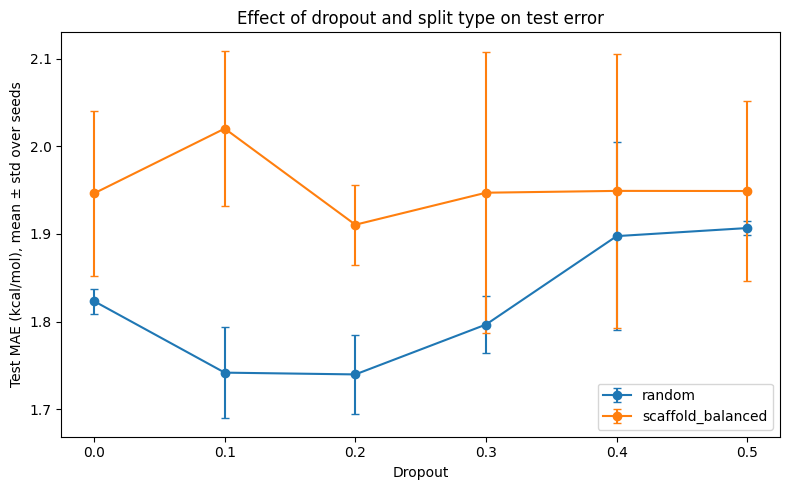

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in main.groupby("split"):
    s = g.groupby("dropout")["test_mae"].agg(["mean", "std"])
    ax.errorbar(s.index, s["mean"], yerr=s["std"], marker="o", capsize=3, label=name)
ax.set_xlabel("Dropout"); ax.set_ylabel("Test MAE (kcal/mol), mean ± std over seeds")
ax.set_title("Effect of dropout and split type on test error"); ax.legend()
plt.tight_layout(); plt.savefig("plots_sensitivity_dropout.png", dpi=150); plt.show()

In [9]:
v = main[main["split"] == "scaffold_balanced"].groupby("dropout")["val_mae_scaled"].agg(["mean", "std"])
best = v["mean"].idxmin()
print(v.round(4))
print("Dropout with lowest mean validation MAE:", best)


           mean     std
dropout                
0.0      0.2957  0.0175
0.1      0.2993  0.0158
0.2      0.2840  0.0078
0.3      0.2812  0.0095
0.4      0.2909  0.0153
0.5      0.2959  0.0286
Dropout with lowest mean validation MAE: 0.3


In [10]:
main = res[res["loss"] == "MSE"]                                                       #MAIN GRID, MSE LOSS
sc = main[main["split"] == "scaffold_balanced"]                                        #SCAFFOLD SPLIT RUNS ONLY
rd = main[main["split"] == "random"]                                                   #RANDOM SPLIT RUNS ONLY
loss_rows = res[(res["split"] == "scaffold_balanced") & (res["dropout"] == 0.2)]       #LOSS FUNCTION COMPARISON RUNS

def anova_p(formula, data, term):                                                      #P-VALUE OF ONE TERM IN AN ANOVA TABLE
    return anova_lm(smf.ols(formula, data=data).fit(), typ=2).loc[term, "PR(>F)"]

def paired_p(col, other):                                                              #PAIRED T-TEST OF A LOSS FUNCTION AGAINST MSE, PAIRED BY SEED
    p = loss_rows.pivot(index="seed", columns="loss", values=col)
    return stats.ttest_rel(p[other], p["MSE"]).pvalue

rows = [
    ("Split type (test MAE, all main-grid runs)",   anova_p("test_mae ~ C(seed)+C(split)*C(dropout)", main, "C(split)")),
    ("Dropout, scaffold split (test MAE)",          anova_p("test_mae ~ C(seed)+C(dropout)", sc, "C(dropout)")),
    ("Dropout, scaffold split (validation MAE)",    anova_p("val_mae_scaled ~ C(seed)+C(dropout)", sc, "C(dropout)")),
    ("Dropout, random split (test MAE)",            anova_p("test_mae ~ C(seed)+C(dropout)", rd, "C(dropout)")),
    ("Dropout, random split (validation MAE)",      anova_p("val_mae_scaled ~ C(seed)+C(dropout)", rd, "C(dropout)")),
    ("Split x dropout interaction (test MAE)",      anova_p("test_mae ~ C(seed)+C(split)*C(dropout)", main, "C(split):C(dropout)")),
    ("Loss: MAE vs MSE (test MAE)",                 paired_p("test_mae", "MAE")),
    ("Loss: RMSE vs MSE (test MAE)",                paired_p("test_mae", "RMSE")),
    ("Loss: MAE vs MSE (validation MAE)",           paired_p("val_mae_scaled", "MAE")),
]
summary = pd.DataFrame(rows, columns=["Comparison", "p-value"])
summary["Significant (p<0.05)"] = np.where(summary["p-value"] < 0.05, "yes", "no")
summary["p-value"] = summary["p-value"].round(4)
print(summary.to_string(index=False))                                                  #ONE TABLE OF EVERY STATISTICAL TEST
summary.to_csv("sensitivity_summary_tests.csv", index=False)

rank = (sc.assign(loss="MSE").pipe(lambda d: pd.concat([d, res[(res["split"] == "scaffold_balanced") & (res["loss"] != "MSE")]]))
        .groupby(["dropout", "loss"]).agg(val_mae=("val_mae_scaled", "mean"), test_mae=("test_mae", "mean"),
                                          test_mae_sd=("test_mae", "std"), test_rmse=("test_rmse", "mean"))
        .sort_values("val_mae").round(3))
print("\nRANKING OF ALL SCAFFOLD CONFIGURATIONS BY MEAN VALIDATION MAE")                #BEST CONFIGURATION AT THE TOP
print(rank)
rank.to_csv("sensitivity_scaffold_ranking.csv")


                               Comparison  p-value Significant (p<0.05)
Split type (test MAE, all main-grid runs)   0.0001                  yes
       Dropout, scaffold split (test MAE)   0.8106                   no
 Dropout, scaffold split (validation MAE)   0.4334                   no
         Dropout, random split (test MAE)   0.0057                  yes
   Dropout, random split (validation MAE)   0.0039                  yes
   Split x dropout interaction (test MAE)   0.2243                   no
              Loss: MAE vs MSE (test MAE)   0.0184                  yes
             Loss: RMSE vs MSE (test MAE)   0.3170                   no
        Loss: MAE vs MSE (validation MAE)   0.0250                  yes

RANKING OF ALL SCAFFOLD CONFIGURATIONS BY MEAN VALIDATION MAE
              val_mae  test_mae  test_mae_sd  test_rmse
dropout loss                                           
0.2     MAE     0.251     1.754        0.026      2.774
        RMSE    0.267     1.847        0.038     

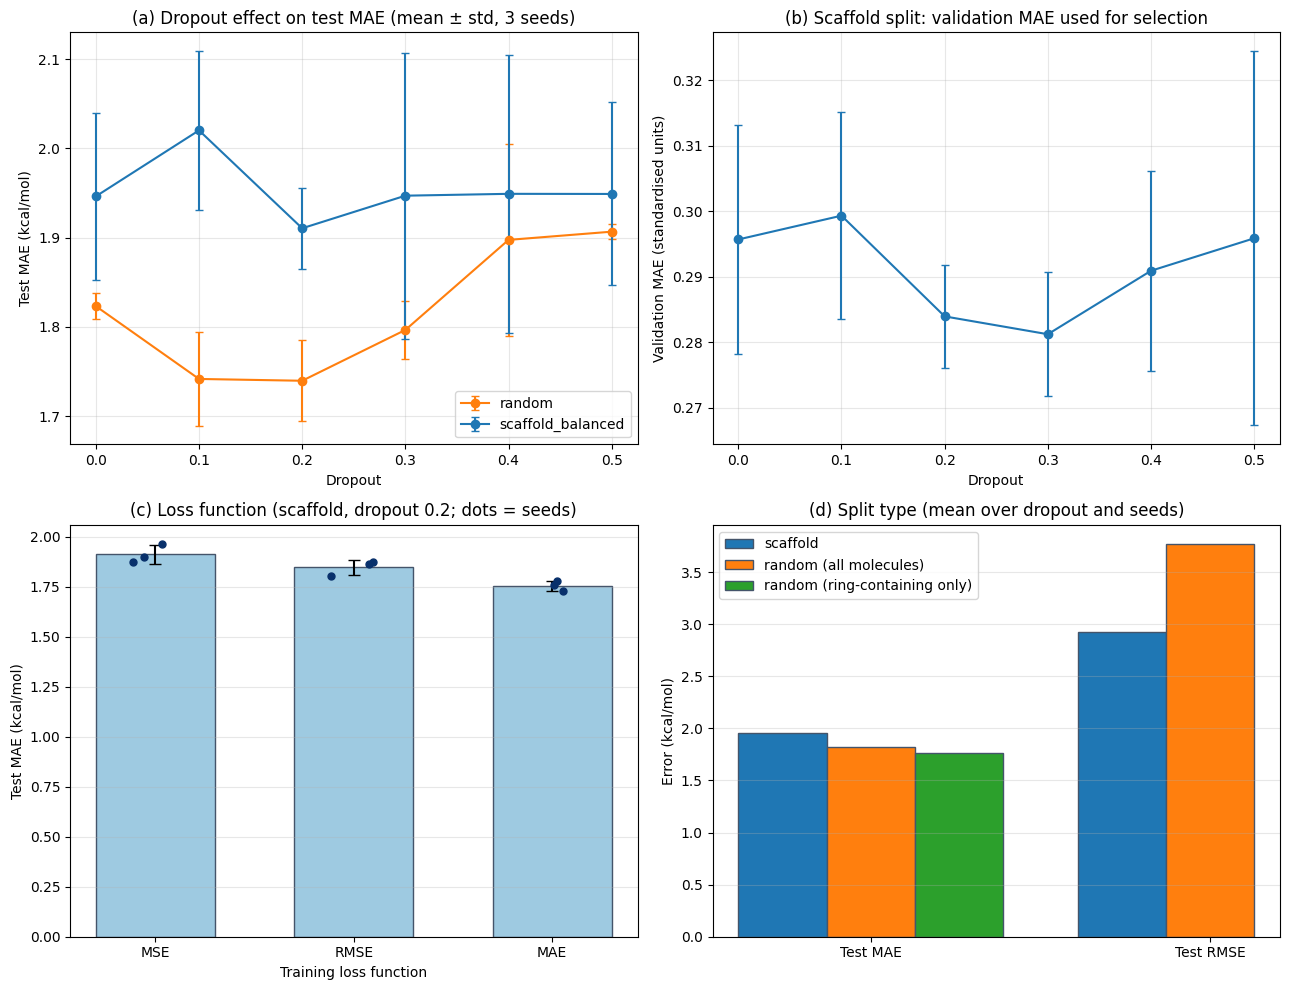

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
colours = {"scaffold_balanced": "#1f77b4", "random": "#ff7f0e"}
rng = np.random.default_rng(0)

# (a) TEST MAE VS DROPOUT FOR BOTH SPLITS
ax = axes[0, 0]
for name, g in main.groupby("split"):
    s = g.groupby("dropout")["test_mae"].agg(["mean", "std"])
    ax.errorbar(s.index, s["mean"], yerr=s["std"], marker="o", capsize=3, color=colours[name], label=name)
ax.set_xlabel("Dropout"); ax.set_ylabel("Test MAE (kcal/mol)")
ax.set_title("(a) Dropout effect on test MAE (mean ± std, 3 seeds)"); ax.legend(); ax.grid(alpha=0.3)

# (b) VALIDATION MAE VS DROPOUT, SCAFFOLD (USED TO CHOOSE DROPOUT)
ax = axes[0, 1]
v = sc.groupby("dropout")["val_mae_scaled"].agg(["mean", "std"])
ax.errorbar(v.index, v["mean"], yerr=v["std"], marker="o", capsize=3, color=colours["scaffold_balanced"])
ax.set_xlabel("Dropout"); ax.set_ylabel("Validation MAE (standardised units)")
ax.set_title("(b) Scaffold split: validation MAE used for selection"); ax.grid(alpha=0.3)

# (c) LOSS FUNCTION COMPARISON, WITH INDIVIDUAL SEEDS SHOWN
ax = axes[1, 0]
order = ["MSE", "RMSE", "MAE"]
for i, l in enumerate(order):
    vals = loss_rows.loc[loss_rows["loss"] == l, "test_mae"].values
    ax.bar(i, vals.mean(), yerr=vals.std(ddof=1), capsize=4, color="#9ecae1", edgecolor="#44546a", width=0.6)
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(vals)), vals, color="#08306b", s=25, zorder=3)
ax.set_xticks(range(3)); ax.set_xticklabels(order)
ax.set_xlabel("Training loss function"); ax.set_ylabel("Test MAE (kcal/mol)")
ax.set_title("(c) Loss function (scaffold, dropout 0.2; dots = seeds)"); ax.grid(axis="y", alpha=0.3)

# (d) SPLIT TYPE COMPARISON
ax = axes[1, 1]
sm = main.groupby("split").agg(mae=("test_mae", "mean"), rmse=("test_rmse", "mean"), ring=("test_mae_ring_only", "mean"))
bars = {"scaffold": [sm.loc["scaffold_balanced", "mae"], sm.loc["scaffold_balanced", "rmse"]],
        "random (all molecules)": [sm.loc["random", "mae"], sm.loc["random", "rmse"]],
        "random (ring-containing only)": [sm.loc["random", "ring"], np.nan]}
x = np.arange(2); w = 0.26
for k, (lab, vals) in enumerate(bars.items()):
    ax.bar(x + (k - 1) * w, vals, w, label=lab, edgecolor="#44546a")
ax.set_xticks(x); ax.set_xticklabels(["Test MAE", "Test RMSE"]); ax.set_ylabel("Error (kcal/mol)")
ax.set_title("(d) Split type (mean over dropout and seeds)"); ax.legend(); ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("plots_sensitivity_summary.png", dpi=150)
plt.show()


In [ ]:
# SELF-CONTAINED CHECK OF THE NUMBERS NOT PRINTED ELSEWHERE 
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

res = pd.read_csv("factorial_dHfus.csv")                                                    # FUSION ENTHALPY FACTORIAL RESULTS
main = res[res["loss"] == "MSE"]                                                            # MAIN GRID, MSE LOSS

print(main.groupby("split")[["test_mae", "test_mae_ring_only", "test_rmse"]].mean().round(3))   # SPLIT MEANS (MSE GRID)
for y in ["test_mae_ring_only", "test_rmse"]:
    a = anova_lm(smf.ols(f"{y} ~ C(seed)+C(split)*C(dropout)", data=main).fit(), typ=2)
    print(y, "split p =", round(a.loc["C(split)", "PR(>F)"], 5))
print("RUNS AT 50 EPOCHS:", int((res["epochs"] >= 50).sum()), "| BY SPLIT:", (res["epochs"] >= 50).groupby(res["split"]).sum().to_dict())


                   test_mae  test_mae_ring_only  test_rmse
split                                                     
random                1.818               1.761      3.766
scaffold_balanced     1.954               1.954      2.926
test_mae_ring_only split p = 0.0
test_rmse split p = 1e-05
RUNS AT 50 EPOCHS: 10 | BY SPLIT: {'random': 8, 'scaffold_balanced': 2}


In [ ]:
#MELTING POINT TEMPERATURE SENSITIVITY TESTS (SAME TESTS AS FUSION ENTHALPY, REDUCED DESIGN: SCAFFOLD SPLIT ONLY, 3 SEEDS)
res_tm = pd.read_csv("factorial_Tm.csv")                                                #MELTING POINT TEMPERATURE RESULTS (15 RUNS)
print("Runs:", len(res_tm), "| seeds:", res_tm["seed"].nunique())                        #SHOULD BE 15 RUNS, 3 SEEDS

main_tm = res_tm[res_tm["loss"] == "MSE"]                                               #MAIN GRID USES MSE LOSS (DROPOUT 0, 0.2, 0.4)
loss_rows_tm = res_tm[res_tm["dropout"] == 0.2]                                         #LOSS FUNCTION COMPARISON RUNS (DROPOUT 0.2)

def anova_p_tm(formula, data, term):                                                    #P-VALUE OF ONE TERM IN A SEED-BLOCKED ANOVA
    return anova_lm(smf.ols(formula, data=data).fit(), typ=2).loc[term, "PR(>F)"]

def paired_p_tm(col, other):                                                            #PAIRED T-TEST OF A LOSS FUNCTION AGAINST MSE, PAIRED BY SEED
    p = loss_rows_tm.pivot(index="seed", columns="loss", values=col)
    return stats.ttest_rel(p[other], p["MSE"]).pvalue

rows_tm = [
    ("Dropout (test MAE)",                  anova_p_tm("test_mae ~ C(seed)+C(dropout)", main_tm, "C(dropout)")),
    ("Dropout (validation MAE)",            anova_p_tm("val_mae_scaled ~ C(seed)+C(dropout)", main_tm, "C(dropout)")),
    ("Loss: MAE vs MSE (test MAE)",         paired_p_tm("test_mae", "MAE")),
    ("Loss: RMSE vs MSE (test MAE)",        paired_p_tm("test_mae", "RMSE")),
    ("Loss: MAE vs MSE (validation MAE)",   paired_p_tm("val_mae_scaled", "MAE")),
    ("Loss: RMSE vs MSE (validation MAE)",  paired_p_tm("val_mae_scaled", "RMSE")),
]
summary_tm = pd.DataFrame(rows_tm, columns=["Comparison", "p-value"])
summary_tm["Significant (p<0.05)"] = np.where(summary_tm["p-value"] < 0.05, "yes", "no")
summary_tm["p-value"] = summary_tm["p-value"].round(4)
print(summary_tm.to_string(index=False))
summary_tm.to_csv("sensitivity_summary_tests_Tm.csv", index=False)                     #SAVES THE TABLE FOR THE REPORT

print("\nMEAN TEST AND VALIDATION MAE PER SETTING")
print(res_tm.groupby(["loss", "dropout"]).agg(val_mae=("val_mae_scaled", "mean"), test_mae=("test_mae", "mean")).round(3))
print("\nMEAN TEST MAE PER SEED (EACH SEED HAS A DIFFERENT TEST SET)")
print(res_tm.groupby("seed")["test_mae"].mean().round(2))
print("\nRUNS THAT REACHED THE 50 EPOCH LIMIT:", int((res_tm["epochs"] == 50).sum()))


Runs: 15 | seeds: 3
                        Comparison  p-value Significant (p<0.05)
                Dropout (test MAE)   0.3992                   no
          Dropout (validation MAE)   0.3926                   no
       Loss: MAE vs MSE (test MAE)   0.6081                   no
      Loss: RMSE vs MSE (test MAE)   0.2192                   no
 Loss: MAE vs MSE (validation MAE)   0.0553                   no
Loss: RMSE vs MSE (validation MAE)   0.2425                   no

MEAN TEST AND VALIDATION MAE PER SETTING
              val_mae  test_mae
loss dropout                   
MAE  0.2        0.531    33.026
MSE  0.0        0.537    33.238
     0.2        0.538    33.251
     0.4        0.527    32.268
RMSE 0.2        0.531    32.583

MEAN TEST MAE PER SEED (EACH SEED HAS A DIFFERENT TEST SET)
seed
0    33.47
1    33.33
2    31.83
Name: test_mae, dtype: float64

RUNS THAT REACHED THE 50 EPOCH LIMIT: 2


In [15]:
import scipy, statsmodels
print("SciPy:", scipy.__version__)
print("statsmodels:", statsmodels.__version__)

SciPy: 1.17.1
statsmodels: 0.15.0
